In [51]:
import numpy as np


np.random.seed(42)


X = np.random.randn(1000, 5, 1)


y = (X.sum(axis=(1, 2)) > 0).astype(int)


y = y.reshape(-1, 1)


print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (1000, 5, 1)
Output shape: (1000, 1)


In [52]:
import numpy as np
import pandas as pd

# Step 1: Generate dataset
np.random.seed(42)

X = np.random.randn(1000, 5, 1)

# Step 2: Generate labels
y = (X.sum(axis=(1, 2)) > 0).astype(int)

# Step 3: Reshape labels
y = y.reshape(-1, 1)

# Step 4: Convert 3D input into 2D
X_2D = X.reshape(1000, 5)

# Step 5: Create DataFrame
df = pd.DataFrame(
    X_2D,
    columns=['time_step_1', 'time_step_2',
             'time_step_3', 'time_step_4',
             'time_step_5']
)

# Step 6: Add labels
df['label'] = y

# Step 7: Save as CSV
df.to_csv('RNN_Dataset.csv', index=False)

print("Dataset saved successfully!")
print(df.head())
print("Dataset shape:", df.shape)

Dataset saved successfully!
   time_step_1  time_step_2  time_step_3  time_step_4  time_step_5  label
0     0.496714    -0.138264     0.647689     1.523030    -0.234153      1
1    -0.234137     1.579213     0.767435    -0.469474     0.542560      1
2    -0.463418    -0.465730     0.241962    -1.913280    -1.724918      0
3    -0.562288    -1.012831     0.314247    -0.908024    -1.412304      0
4     1.465649    -0.225776     0.067528    -1.424748    -0.544383      0
Dataset shape: (1000, 6)


In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 5, 1)
X_test: (200, 5, 1)
y_train: (800, 1)
y_test: (200, 1)


In [54]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(5, 1)),

    layers.SimpleRNN(16, activation='tanh'),

    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

In [55]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [56]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.6781 - loss: 0.6294 - val_accuracy: 0.7563 - val_loss: 0.5861
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8313 - loss: 0.5353 - val_accuracy: 0.8625 - val_loss: 0.5002
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9172 - loss: 0.4480 - val_accuracy: 0.9125 - val_loss: 0.4127
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9344 - loss: 0.3673 - val_accuracy: 0.9187 - val_loss: 0.3362
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9266 - loss: 0.3081 - val_accuracy: 0.9187 - val_loss: 0.2853
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9203 - loss: 0.2699 - val_accuracy: 0.9375 - val_loss: 0.2518
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9312 - loss: 0.2442 - val_accuracy: 0.9438 - val_loss: 0.2288
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9375 - loss: 0.2242 - val_accuracy: 0.9438 - val_loss

In [57]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9550 - loss: 0.1453  
Test Loss: 0.1453039050102234
Test Accuracy: 95.49999833106995 %


In [58]:
predictions = model.predict(X_test)

predicted_labels = (predictions >= 0.5).astype(int)

print("Actual labels:", y_test[:10].flatten())
print("Predicted labels:", predicted_labels[:10].flatten())

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Actual labels: [0 1 1 0 1 0 0 0 0 0]
Predicted labels: [0 1 1 0 0 0 0 0 0 0]


In [59]:
import numpy as np

np.random.seed(42)

# Generate 1000 sequences
X = np.random.randn(1000, 5, 1)

# Generate labels
y = (X.sum(axis=(1, 2)) > 0).astype(int)

# Reshape labels
y = y.reshape(-1, 1)

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (1000, 5, 1)
Output shape: (1000, 1)


actual

In [60]:
import numpy as np

class SimpleRNN:

    def __init__(self, input_size, hidden_size, output_size,
                 learning_rate=0.01):

        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate

        # Initialize weights
        self.Wxh = np.random.randn(input_size, hidden_size) * 0.1
        self.Whh = np.random.randn(hidden_size, hidden_size) * 0.1
        self.Why = np.random.randn(hidden_size, output_size) * 0.1

        # Initialize biases
        self.bh = np.zeros((1, hidden_size))
        self.by = np.zeros((1, output_size))

    # Tanh activation
    def tanh(self, x):
        return np.tanh(x)

    # Sigmoid activation
    def sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x,-500,500)))

In [61]:
np.random.seed(42)

model = SimpleRNN(
    input_size=1,
    hidden_size=8,
    output_size=1,
    learning_rate=0.01
)

In [62]:
print("Input to Hidden:", model.Wxh.shape)
print("Hidden to Hidden:", model.Whh.shape)
print("Hidden to Output:", model.Why.shape)

print("Hidden Bias:", model.bh.shape)
print("Output Bias:", model.by.shape)

Input to Hidden: (1, 8)
Hidden to Hidden: (8, 8)
Hidden to Output: (8, 1)
Hidden Bias: (1, 8)
Output Bias: (1, 1)


In [63]:
model = SimpleRNN(1, 8, 1)

print("Tanh output:", model.tanh(np.array([-2, 0, 2])))

print("Sigmoid output:", model.sigmoid(np.array([-2, 0, 2])))

Tanh output: [-0.96402758  0.          0.96402758]
Sigmoid output: [0.11920292 0.5        0.88079708]


In [64]:
values= np.array([-2,-1,0,2])
print("Tanh:",np.tanh(values))
print("sigmoid:", 1/(1+np.exp(-values)))

Tanh: [-0.96402758 -0.76159416  0.          0.96402758]
sigmoid: [0.11920292 0.26894142 0.5        0.88079708]


In [65]:
def forward(self, X):

    # Get batch size and sequence length
    batch_size, sequence_length, _ = X.shape

    # Initialize hidden state with zeros
    h = np.zeros((batch_size, self.hidden_size))

    # Store initial hidden state
    self.hidden_states = [h]

    # Store inputs
    self.inputs = X

    # Process sequence one time step at a time
    for t in range(sequence_length):

        # Extract input at current time step
        xt = X[:, t, :]

        # Calculate new hidden state
        h = self.tanh(
            xt @ self.Wxh +
            h @ self.Whh +
            self.bh
        )

        # Store hidden state
        self.hidden_states.append(h.copy())

    # Calculate output
    logits = h @ self.Why + self.by

    # Apply sigmoid activation
    y_pred = self.sigmoid(logits)

    return y_pred

In [66]:
pip install --upgrade numpy

In [67]:
import numpy as np

np.random.seed(42)

X = np.random.randn(1000, 5, 1)

y = (X.sum(axis=(1, 2)) > 0).astype(int)

y = y.reshape(-1, 1)

print(type(X))
print("Input shape:", X.shape)
print("Output shape:", y.shape)

<class 'numpy.ndarray'>
Input shape: (1000, 5, 1)
Output shape: (1000, 1)


In [68]:
pip install numpy

In [74]:
np.random.seed(42)

# Instantiate the fully defined VanillaRNN class
model = VanillaRNN(input_size=1, hidden_size=8, output_size=1)

# Run forward propagation on the 3D test dataset
y_pred = model.forward(X_test)

print("Input shape:", X_test.shape)
print("Prediction shape:", y_pred.shape)
print("Hidden states stored:", len(model.hidden_states))
print("First 5 predictions:\n", y_pred[:5])

Input shape: (200, 5, 1)
Prediction shape: (200, 1)
Hidden states stored: 6
First 5 predictions:
 [[0.49256554]
 [0.50072586]
 [0.5010506 ]
 [0.49474788]
 [0.49904247]]


In [71]:

def forward(self, X):

    # Get batch size and sequence length
    batch_size, sequence_length, _ = X.shape

    # Initialize hidden state
    h = np.zeros((batch_size, self.hidden_size))

    self.hidden_states = [h]
    self.inputs = X

    # Process sequence one time step at a time
    for t in range(sequence_length):

        # Get current input
        x_t = X[:, t, :]

        # Calculate new hidden state
        h = np.tanh(
            x_t @ self.Wxh +
            h @ self.Whh +
            self.bh
        )

        self.hidden_states.append(h.copy())

    # Calculate output
    logits = h @ self.Why + self.by

    # Apply sigmoid activation
    y_pred = self.sigmoid(logits)

    return y_pred


In [72]:

def forward(self, X):

    # Get batch size and sequence length
    batch_size, sequence_length, _ = X.shape

    # Initialize hidden state
    h = np.zeros((batch_size, self.hidden_size))

    self.hidden_states = [h]
    self.inputs = X

    # Process sequence one time step at a time
    for t in range(sequence_length):

        # Get current input
        x_t = X[:, t, :]

        # Calculate new hidden state
        h = np.tanh(
            x_t @ self.Wxh +
            h @ self.Whh +
            self.bh
        )

        self.hidden_states.append(h.copy())

    # Calculate output
    logits = h @ self.Why + self.by

    # Apply sigmoid activation
    y_pred = self.sigmoid(logits)

    return y_pred


In [73]:
X = np.array([
    [1.0],
    [0.1],
    [1.1]
])

In [75]:

import numpy as np

class SimpleRNN:

    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01):

        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.learning_rate = learning_rate

        # Initialize weights
        self.Wxh = np.random.randn(input_size, hidden_size) * 0.1
        self.Whh = np.random.randn(hidden_size, hidden_size) * 0.1
        self.Why = np.random.randn(hidden_size, output_size) * 0.1

        # Initialize biases
        self.bh = np.zeros((1, hidden_size))
        self.by = np.zeros((1, output_size))

    def tanh(self, x):
        return np.tanh(x)

    def sigmoid(self, x):
        x = np.clip(x, -500, 500)
        return 1 / (1 + np.exp(-x))

    # ---------------- FORWARD PROPAGATION ----------------

    def forward(self, X):

        batch_size, sequence_length, _ = X.shape

        h = np.zeros((batch_size, self.hidden_size))

        self.hidden_states = [h]
        self.inputs = X

        for t in range(sequence_length):

            x_t = X[:, t, :]

            h = self.tanh(
                x_t @ self.Wxh +
                h @ self.Whh +
                self.bh
            )

            self.hidden_states.append(h.copy())

        logits = h @ self.Why + self.by

        y_pred = self.sigmoid(logits)

        self.y_pred = y_pred

        return y_pred

    # ---------------- BACKWARD PROPAGATION (BPTT) ----------------

    def backward(self, y_true):

        batch_size, sequence_length, _ = self.inputs.shape

        # 1. Output gradient (Sigmoid + Binary Cross Entropy)
        d_logits = self.y_pred - y_true

        # Average gradient across batch
        d_logits = d_logits / batch_size

        # 2. Output weight gradients
        h_last = self.hidden_states[-1]

        dWhy = h_last.T @ d_logits
        dby = np.sum(d_logits, axis=0, keepdims=True)

        # 3. Gradient flowing into final hidden state
        dh_next = d_logits @ self.Why.T

        # Initialize other gradients
        dWxh = np.zeros_like(self.Wxh)
        dWhh = np.zeros_like(self.Whh)
        dbh = np.zeros_like(self.bh)

        # 4. Backpropagate through time
        for t in reversed(range(sequence_length)):

            h = self.hidden_states[t + 1]
            h_prev = self.hidden_states[t]

            x_t = self.inputs[:, t, :]

            # Tanh derivative
            da = dh_next * (1 - h ** 2)

            # Input-to-hidden weight gradient
            dWxh += x_t.T @ da

            # Hidden-to-hidden weight gradient
            dWhh += h_prev.T @ da

            # Hidden bias gradient
            dbh += np.sum(da, axis=0, keepdims=True)

            # Gradient for previous hidden state
            dh_next = da @ self.Whh.T

        # 5. Gradient clipping
        for grad in [dWxh, dWhh, dWhy, dbh, dby]:
            np.clip(grad, -1, 1, out=grad)

        # 6. Update weights
        self.Wxh -= self.learning_rate * dWxh
        self.Whh -= self.learning_rate * dWhh
        self.Why -= self.learning_rate * dWhy

        self.bh -= self.learning_rate * dbh
        self.by -= self.learning_rate * dby

        return {
            "dWxh": dWxh,
            "dWhh": dWhh,
            "dWhy": dWhy,
            "dbh": dbh,
            "dby": dby
        }


In [76]:
# Check current shape
print("Before reshaping:", X.shape)

# Reshape input for RNN
X = X.reshape(X.shape[0], X.shape[1], 1)

# Check new shape
print("After reshaping:", X.shape)
print("Target shape:", y.shape)

Before reshaping: (3, 1)
After reshaping: (3, 1, 1)
Target shape: (1000, 1)


In [79]:

import numpy as np

np.random.seed(42)

# Generate 1000 samples, 5 time steps, 1 feature
X = np.random.randn(1000, 5, 1)

# Generate labels
y = (X.sum(axis=(1, 2)) > 0).astype(int)

# Reshape labels
y = y.reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (1000, 5, 1)
y shape: (1000, 1)


In [80]:
y_pred = model.forward(X)

print("Prediction shape:", y_pred.shape)

Prediction shape: (1000, 1)


In [81]:
# Activity 3 dataset
X_activity3 = np.array([
    [[1.0], [0.1], [1.1]]
])

print(X_activity3.shape)  # (1, 3, 1)

(1, 3, 1)


In [82]:

# Save the initial weights
np.random.seed(42)

initial_model = SimpleRNN(
    input_size=1,
    hidden_size=8,
    output_size=1,
    learning_rate=0.01
)

initial_weights = {
    "Wxh": initial_model.Wxh.copy(),
    "Whh": initial_model.Whh.copy(),
    "Why": initial_model.Why.copy(),
    "bh": initial_model.bh.copy(),
    "by": initial_model.by.copy()
}

# Loss function
def binary_cross_entropy(y_true, y_pred):
    eps = 1e-8
    y_pred = np.clip(y_pred, eps, 1 - eps)

    return -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )


# Compare different epoch counts
epoch_values = [50, 100, 200]

results = {}

for epochs in epoch_values:

    # Create a fresh model
    model = SimpleRNN(
        input_size=1,
        hidden_size=8,
        output_size=1,
        learning_rate=0.01
    )

    # Restore identical initial weights
    model.Wxh = initial_weights["Wxh"].copy()
    model.Whh = initial_weights["Whh"].copy()
    model.Why = initial_weights["Why"].copy()
    model.bh = initial_weights["bh"].copy()
    model.by = initial_weights["by"].copy()

    # Train
    for epoch in range(epochs):

        y_pred = model.forward(X)

        loss = binary_cross_entropy(y, y_pred)

        model.backward(y)

    # Evaluate final loss after the last update
    final_prediction = model.forward(X)
    final_loss = binary_cross_entropy(y, final_prediction)

    results[epochs] = final_loss

    print(f"Epochs: {epochs}, Final Loss: {final_loss:.6f}")


# Display comparison
print("\nLOSS COMPARISON")

for epochs, loss in results.items():
    print(f"{epochs} Epochs: {loss:.6f}")


Epochs: 50, Final Loss: 0.693403
Epochs: 100, Final Loss: 0.690544
Epochs: 200, Final Loss: 0.685104

LOSS COMPARISON
50 Epochs: 0.693403
100 Epochs: 0.690544
200 Epochs: 0.685104


In [83]:

import numpy as np
import pandas as pd

# Generate test dataset
np.random.seed(100)

X_test = np.random.randn(10, 5, 1)

# Step 1: Calculate actual sums
actual_sums = X_test.sum(axis=(1, 2))

# Step 2: Generate actual labels
actual_labels = (actual_sums > 0).astype(int)

# Step 3: Generate predictions using trained Vanilla RNN
predicted_probabilities = model.forward(X_test)

# Step 4: Generate predicted labels
predicted_labels = (predicted_probabilities >= 0.5).astype(int).flatten()

# Step 5: Compare actual and predicted
results = pd.DataFrame({
    "Actual Sum": actual_sums,
    "Actual Label": actual_labels,
    "Predicted Probability": predicted_probabilities.flatten(),
    "Predicted Label": predicted_labels
})

results["Correct Prediction"] = (
    results["Actual Label"] == results["Predicted Label"]
)

print(results.to_string(index=False))

# Calculate test accuracy
accuracy = np.mean(actual_labels == predicted_labels) * 100

print("\nTest Accuracy:", round(accuracy, 2), "%")


 Actual Sum  Actual Label  Predicted Probability  Predicted Label  Correct Prediction
   0.474835             1               0.515321                1                True
  -0.269139             0               0.506675                1               False
   0.883109             1               0.512342                1                True
  -1.162413             0               0.491945                0                True
   2.250791             1               0.505614                1                True
   2.759077             1               0.505110                1                True
  -0.410271             0               0.513040                1               False
  -3.545775             0               0.489118                0                True
  -0.518487             0               0.517988                1               False
  -2.501763             0               0.518937                1               False

Test Accuracy: 60.0 %


RNN


In [84]:
np.random.seed(42)

X = np.random.randn(1000, 5, 1)

# Actual labels based on sequence sum
y = (X.sum(axis=(1, 2)) > 0).astype(int)
y = y.reshape(-1, 1)

# Split training and testing data
X_train = X[:800]
X_test = X[800:]

y_train = y[:800]
y_test = y[800:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 5, 1)
X_test: (200, 5, 1)
y_train: (800, 1)
y_test: (200, 1)


In [85]:

class VanillaRNN:

    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.01):

        self.hidden_size = hidden_size
        self.learning_rate = learning_rate

        # Initialize weights
        self.Wxh = np.random.randn(input_size, hidden_size) * 0.1
        self.Whh = np.random.randn(hidden_size, hidden_size) * 0.1
        self.Why = np.random.randn(hidden_size, output_size) * 0.1

        # Initialize biases
        self.bh = np.zeros((1, hidden_size))
        self.by = np.zeros((1, output_size))

    def sigmoid(self, x):
        x = np.clip(x, -500, 500)
        return 1 / (1 + np.exp(-x))

    # FORWARD PROPAGATION
    def forward(self, X):

        batch_size, sequence_length, _ = X.shape

        h = np.zeros((batch_size, self.hidden_size))

        self.hidden_states = [h]
        self.inputs = X

        for t in range(sequence_length):

            x_t = X[:, t, :]

            h = np.tanh(
                x_t @ self.Wxh +
                h @ self.Whh +
                self.bh
            )

            self.hidden_states.append(h.copy())

        logits = h @ self.Why + self.by

        y_pred = self.sigmoid(logits)

        self.y_pred = y_pred

        return y_pred

    # BACKPROPAGATION THROUGH TIME
    def backward(self, y_true):

        batch_size, sequence_length, _ = self.inputs.shape

        # Output gradient
        d_logits = (self.y_pred - y_true) / batch_size

        # Output weight gradients
        h_last = self.hidden_states[-1]

        dWhy = h_last.T @ d_logits
        dby = np.sum(d_logits, axis=0, keepdims=True)

        # Gradient flowing into last hidden state
        dh_next = d_logits @ self.Why.T

        # Initialize gradients
        dWxh = np.zeros_like(self.Wxh)
        dWhh = np.zeros_like(self.Whh)
        dbh = np.zeros_like(self.bh)

        # BPTT: last time step to first
        for t in reversed(range(sequence_length)):

            h = self.hidden_states[t + 1]
            h_prev = self.hidden_states[t]

            x_t = self.inputs[:, t, :]

            # Tanh derivative
            da = dh_next * (1 - h ** 2)

            # Weight gradients
            dWxh += x_t.T @ da
            dWhh += h_prev.T @ da

            # Bias gradient
            dbh += np.sum(da, axis=0, keepdims=True)

            # Send gradient to previous hidden state
            dh_next = da @ self.Whh.T

        # Gradient clipping
        for grad in [dWxh, dWhh, dWhy, dbh, dby]:
            np.clip(grad, -1, 1, out=grad)

        # Update weights
        self.Wxh -= self.learning_rate * dWxh
        self.Whh -= self.learning_rate * dWhh
        self.Why -= self.learning_rate * dWhy

        self.bh -= self.learning_rate * dbh
        self.by -= self.learning_rate * dby


In [ ]:
def binary_cross_entropy(y_true, y_pred):

    eps = 1e-8
    y_pred = np.clip(y_pred, eps, 1 - eps)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [86]:
np.random.seed(42)

model = VanillaRNN(
    input_size=1,
    hidden_size=8,
    output_size=1,
    learning_rate=0.01
)

epochs = 100

for epoch in range(epochs):

    y_pred = model.forward(X_train)

    loss = binary_cross_entropy(y_train, y_pred)

    model.backward(y_train)

    if (epoch + 1) % 10 == 0:

        predicted_labels = (y_pred >= 0.5).astype(int)

        accuracy = np.mean(predicted_labels == y_train)

        print(
            f"Epoch: {epoch+1}, "
            f"Loss: {loss:.4f}, "
            f"Accuracy: {accuracy:.4f}"
        )

Epoch: 10, Loss: 0.6959, Accuracy: 0.3613
Epoch: 20, Loss: 0.6953, Accuracy: 0.3862
Epoch: 30, Loss: 0.6946, Accuracy: 0.4088
Epoch: 40, Loss: 0.6939, Accuracy: 0.4662
Epoch: 50, Loss: 0.6933, Accuracy: 0.5162
Epoch: 60, Loss: 0.6926, Accuracy: 0.5200
Epoch: 70, Loss: 0.6920, Accuracy: 0.5200
Epoch: 80, Loss: 0.6914, Accuracy: 0.5225
Epoch: 90, Loss: 0.6908, Accuracy: 0.5400
Epoch: 100, Loss: 0.6902, Accuracy: 0.5513


In [87]:
# Predict using test data
y_pred = model.forward(X_test)

# Actual sequence sums
actual_sums = X_test.sum(axis=(1, 2))

# Actual labels
actual_labels = (actual_sums > 0).astype(int)

# Predicted labels
predicted_labels = (y_pred >= 0.5).astype(int).flatten()

# Comparison table
results = pd.DataFrame({
    "Actual Sum": actual_sums,
    "Actual Label": actual_labels,
    "Predicted Probability": y_pred.flatten(),
    "Predicted Label": predicted_labels
})

results["Correct"] = (
    results["Actual Label"] == results["Predicted Label"]
)

print(results.head(20))

# Test accuracy
accuracy = np.mean(actual_labels == predicted_labels) * 100

print("Test Accuracy:", round(accuracy, 2), "%")

    Actual Sum  Actual Label  Predicted Probability  Predicted Label  Correct
0    -1.770908             0               0.500687                1    False
1    -2.596656             0               0.506544                1    False
2    -2.248313             0               0.504368                1    False
3    -0.969574             0               0.504748                1    False
4    -1.000642             0               0.502287                1    False
5     1.041473             1               0.507944                1     True
6    -5.353617             0               0.500946                1    False
7     0.540951             1               0.502716                1     True
8     0.586833             1               0.507764                1     True
9     3.389219             1               0.507170                1     True
10   -0.921387             0               0.501856                1    False
11    2.842169             1               0.504753             

In [88]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import time
import pandas as pd

In [89]:
torch.manual_seed(42)

# Dataset settings
num_samples = 3000
sequence_length = 50
input_size = 1

# Generate input sequences
X = torch.randn(num_samples, sequence_length, input_size)

# Generate labels using the first time step
y = (X[:, 0, 0] > 0).float().unsqueeze(1)

# Split dataset: 70% training, 15% validation, 15% testing
X_train, X_val, X_test = X[:2100], X[2100:2550], X[2550:]
y_train, y_val, y_test = y[:2100], y[2100:2550], y[2550:]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: torch.Size([2100, 50, 1]) torch.Size([2100, 1])
Validation: torch.Size([450, 50, 1]) torch.Size([450, 1])
Testing: torch.Size([450, 50, 1]) torch.Size([450, 1])


In [90]:

# Common model settings
input_size = 1
hidden_size = 32
output_size = 1


# 1. Vanilla RNN
class VanillaRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size,
            hidden_size,
            batch_first=True,
            nonlinearity="tanh"
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):

        output, hidden = self.rnn(x)

        # Last hidden state
        last_hidden = hidden[-1]

        return self.fc(last_hidden)


# 2. LSTM
class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size,
            hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        last_hidden = hidden[-1]

        return self.fc(last_hidden)


# 3. GRU
class GRUModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.gru = nn.GRU(
            input_size,
            hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):

        output, hidden = self.gru(x)

        last_hidden = hidden[-1]

        return self.fc(last_hidden)


In [91]:
models = {
    "Vanilla RNN": VanillaRNN(),
    "LSTM": LSTMModel(),
    "GRU": GRUModel()
}

for name, model in models.items():

    total_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print(name, "Parameters:", total_params)

Vanilla RNN Parameters: 1153
LSTM Parameters: 4513
GRU Parameters: 3393


In [92]:

# Prepare DataLoader
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# Loss function
criterion = nn.BCEWithLogitsLoss()

# Training settings
epochs = 15
learning_rate = 0.001

results = []

for name, model in models.items():

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for batch_X, batch_y in train_loader:

            # Forward propagation
            outputs = model(batch_X)

            loss = criterion(outputs, batch_y)

            # Backpropagation
            optimizer.zero_grad()

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        # Validation
        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_loss = criterion(
                val_outputs,
                y_val
            )

            val_predictions = (
                torch.sigmoid(val_outputs) >= 0.5
            ).float()

            val_accuracy = (
                val_predictions == y_val
            ).float().mean().item() * 100

        if (epoch + 1) % 5 == 0:

            print(
                f"{name} | Epoch {epoch+1}/{epochs} "
                f"| Loss: {avg_loss:.4f} "
                f"| Val Loss: {val_loss.item():.4f} "
                f"| Val Accuracy: {val_accuracy:.2f}%"
            )

    training_time = time.time() - start_time

    # Test evaluation
    model.eval()

    with torch.no_grad():

        test_outputs = model(X_test)

        test_loss = criterion(
            test_outputs,
            y_test
        ).item()

        test_predictions = (
            torch.sigmoid(test_outputs) >= 0.5
        ).float()

        test_accuracy = (
            test_predictions == y_test
        ).float().mean().item() * 100

    parameters = sum(
        p.numel() for p in model.parameters()
    )

    results.append({
        "Model": name,
        "Parameters": parameters,
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy,
        "Training Time (sec)": training_time
    })

    print(f"\n{name} training completed!\n")


Vanilla RNN | Epoch 5/15 | Loss: 0.6930 | Val Loss: 0.6903 | Val Accuracy: 53.11%
Vanilla RNN | Epoch 10/15 | Loss: 0.6921 | Val Loss: 0.6892 | Val Accuracy: 53.56%
Vanilla RNN | Epoch 15/15 | Loss: 0.2383 | Val Loss: 0.2167 | Val Accuracy: 91.78%

Vanilla RNN training completed!

LSTM | Epoch 5/15 | Loss: 0.6931 | Val Loss: 0.6928 | Val Accuracy: 52.89%
LSTM | Epoch 10/15 | Loss: 0.6929 | Val Loss: 0.6917 | Val Accuracy: 52.67%
LSTM | Epoch 15/15 | Loss: 0.6926 | Val Loss: 0.6913 | Val Accuracy: 50.89%

LSTM training completed!

GRU | Epoch 5/15 | Loss: 0.6931 | Val Loss: 0.6924 | Val Accuracy: 52.00%
GRU | Epoch 10/15 | Loss: 0.6929 | Val Loss: 0.6926 | Val Accuracy: 52.89%
GRU | Epoch 15/15 | Loss: 0.6932 | Val Loss: 0.6913 | Val Accuracy: 53.33%

GRU training completed!



In [93]:
comparison = pd.DataFrame(results)

print(comparison.round(4))

         Model  Parameters  Test Loss  Test Accuracy  Training Time (sec)
0  Vanilla RNN        1153     0.2083        91.5556               3.8033
1         LSTM        4513     0.6922        52.8889               7.7763
2          GRU        3393     0.6924        52.6667              11.5611


In [94]:
sequence_lengths = [10, 25, 50, 100]

memory_results = []

for name, model in models.items():

    model.eval()

    for length in sequence_lengths:

        # Generate new sequences
        X_long = torch.randn(500, length, 1)

        # Actual label depends on first value
        y_long = (
            X_long[:, 0, 0] > 0
        ).float().unsqueeze(1)

        with torch.no_grad():

            outputs = model(X_long)

            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).float()

            accuracy = (
                predictions == y_long
            ).float().mean().item() * 100

        memory_results.append({
            "Model": name,
            "Sequence Length": length,
            "Accuracy": accuracy
        })


memory_df = pd.DataFrame(memory_results)

print(memory_df.round(2))

          Model  Sequence Length  Accuracy
0   Vanilla RNN               10      77.4
1   Vanilla RNN               25      19.2
2   Vanilla RNN               50      92.6
3   Vanilla RNN              100      45.8
4          LSTM               10      49.8
5          LSTM               25      49.2
6          LSTM               50      50.0
7          LSTM              100      53.2
8           GRU               10      51.4
9           GRU               25      49.8
10          GRU               50      45.0
11          GRU              100      48.6


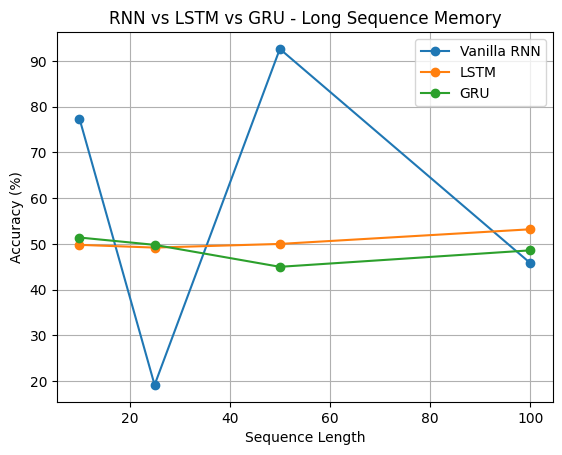

In [95]:
import matplotlib.pyplot as plt

for name in models.keys():

    data = memory_df[
        memory_df["Model"] == name
    ]

    plt.plot(
        data["Sequence Length"],
        data["Accuracy"],
        marker="o",
        label=name
    )

plt.xlabel("Sequence Length")
plt.ylabel("Accuracy (%)")
plt.title("RNN vs LSTM vs GRU - Long Sequence Memory")

plt.legend()
plt.grid(True)
plt.show()

In [96]:
# If needed:
# !pip install torch torchvision matplotlib pandas

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import random

In [97]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [98]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 483kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.38MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.54MB/s]

Training samples: 60000
Testing samples: 10000


Image shape: torch.Size([1, 28, 28])
Label: 5


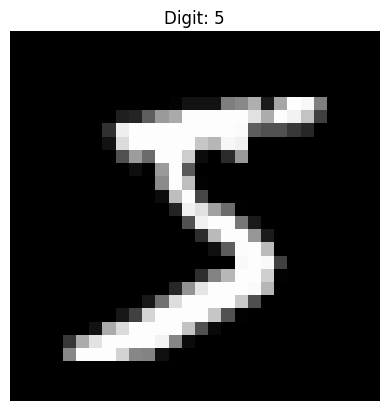

In [99]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Digit: {label}")
plt.axis("off")
plt.show()

In [100]:
def convert_to_sequence(images, mode):

    # images shape: (batch, 1, 28, 28)

    images = images.squeeze(1)

    if mode == "row":
        # 28 time steps, 28 features
        sequences = images

    elif mode == "pixel":
        # 784 time steps, 1 feature
        sequences = images.reshape(images.shape[0], 784, 1)

    return sequences

In [101]:
sample_images = torch.randn(5, 1, 28, 28)

row_data = convert_to_sequence(sample_images, "row")
pixel_data = convert_to_sequence(sample_images, "pixel")

print("Row-wise shape:", row_data.shape)
print("Pixel-wise shape:", pixel_data.shape)

Row-wise shape: torch.Size([5, 28, 28])
Pixel-wise shape: torch.Size([5, 784, 1])


In [102]:
class RNNModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=64,
            batch_first=True
        )

        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        output, hidden = self.rnn(x)
        return self.fc(hidden[-1])


class LSTMModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=64,
            batch_first=True
        )

        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)
        return self.fc(hidden[-1])


class GRUModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=64,
            batch_first=True
        )

        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        output, hidden = self.gru(x)
        return self.fc(hidden[-1])


class CNN1DModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels=input_size,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()

        self.conv2 = nn.Conv1d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.fc = nn.Linear(128, 10)

    def forward(self, x):

        # (batch, time, features)
        # Convert to (batch, features, time)
        x = x.transpose(1, 2)

        x = self.relu(self.conv1(x))
        x = self.relu(self.conv2(x))

        x = self.pool(x)

        x = x.squeeze(-1)

        return self.fc(x)


class TransformerModel(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.embedding = nn.Linear(input_size, 64)

        self.position_embedding = nn.Parameter(
            torch.randn(1, 784, 64) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.fc = nn.Linear(64, 10)

    def forward(self, x):

        x = self.embedding(x)

        # Add positional information
        x = x + self.position_embedding[:, :x.size(1), :]

        x = self.transformer(x)

        # Average the representations of all time steps
        x = x.mean(dim=1)

        return self.fc(x)

In [103]:
BATCH_SIZE = 128
EPOCHS = 3
TRAIN_LIMIT = 12000

# Use the same training samples for every model
generator = torch.Generator().manual_seed(SEED)

indices = torch.randperm(
    len(train_dataset),
    generator=generator
)[:TRAIN_LIMIT].tolist()

train_subset = Subset(train_dataset, indices)

def train_and_evaluate(model, mode):

    model = model.to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.CrossEntropyLoss()

    train_loader = DataLoader(
        train_subset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    start_time = time.time()

    for epoch in range(EPOCHS):

        model.train()

        total_loss = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            sequences = convert_to_sequence(images, mode)

            optimizer.zero_grad()

            outputs = model(sequences)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(train_loader)

        print(
            f"Epoch {epoch+1}/{EPOCHS} "
            f"| Loss: {average_loss:.4f}"
        )

    # Testing
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            sequences = convert_to_sequence(images, mode)

            outputs = model(sequences)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    accuracy = 100 * correct / total

    training_time = time.time() - start_time

    parameter_count = sum(
        p.numel() for p in model.parameters()
    )

    return {
        "Accuracy (%)": accuracy,
        "Parameters": parameter_count,
        "Training Time (seconds)": training_time
    }

In [110]:
model_classes = {
    "RNN": RNNModel,
    "LSTM": LSTMModel,
    "GRU": GRUModel,
    "1D CNN": CNN1DModel
}

results = []

# Only row-wise mode
mode = "row"
input_size = 28

print("\n" + "=" * 50)
print("MODE: ROW-WISE")
print("=" * 50)

for model_name, model_class in model_classes.items():

    print(f"\nTraining {model_name}...")

    torch.manual_seed(SEED)

    model = model_class(input_size)

    metrics = train_and_evaluate(model, mode)

    results.append({
        "Mode": mode,
        "Model": model_name,
        **metrics
    })

    print(
        f"{model_name} Test Accuracy: "
        f"{metrics['Accuracy (%)']:.2f}%"
    )


MODE: ROW-WISE

Training RNN...
Epoch 1/3 | Loss: 1.8153
Epoch 2/3 | Loss: 1.2466
Epoch 3/3 | Loss: 1.0145
RNN Test Accuracy: 71.29%

Training LSTM...
Epoch 1/3 | Loss: 1.9901
Epoch 2/3 | Loss: 0.8771
Epoch 3/3 | Loss: 0.4874
LSTM Test Accuracy: 87.83%

Training GRU...
Epoch 1/3 | Loss: 1.9893
Epoch 2/3 | Loss: 1.0455
Epoch 3/3 | Loss: 0.7860
GRU Test Accuracy: 79.14%

Training 1D CNN...
Epoch 1/3 | Loss: 1.9792
Epoch 2/3 | Loss: 1.5317
Epoch 3/3 | Loss: 1.2503
1D CNN Test Accuracy: 67.10%


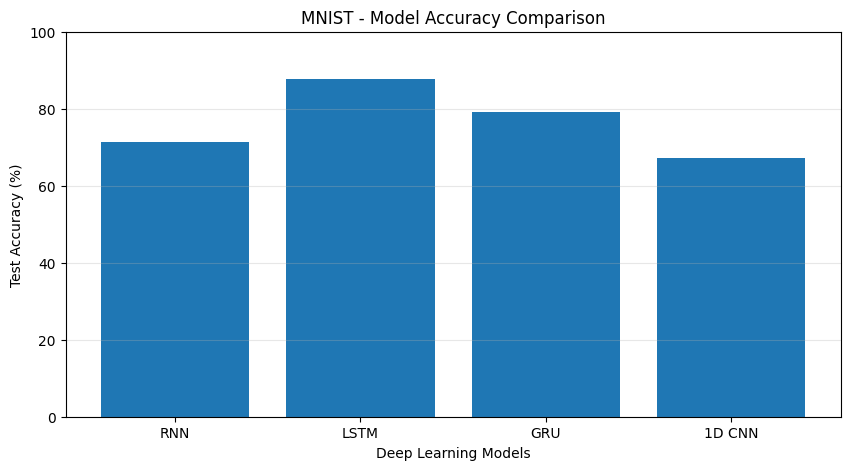

In [111]:
import matplotlib.pyplot as plt

results_df = pd.DataFrame(results)

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy (%)"]
)

plt.title("MNIST - Model Accuracy Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [119]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import copy

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create one initial model
initial_model = RNNModel()

# Save its initial weights
initial_weights = copy.deepcopy(initial_model.state_dict())

In [135]:
def run_gradient_experiment(use_clipping, epochs=15):
    # Re-instantiate RNNModel with input_size=1, hidden_size=32, output_size=1 as used in Section 2
    # Or use a copy of the initial_model weights we saved
    model = RNNModel().to(device)
    model.load_state_dict(initial_weights)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    epoch_losses = []
    gradient_norms = []
    exploded = False
    non_finite = False

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            # REMOVED .unsqueeze(1) because labels are already (batch_size, 1)
            labels = labels.float().to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()

            # Calculate total gradient norm BEFORE clipping
            total_norm = torch.linalg.vector_norm(
                torch.stack([
                    p.grad.detach().norm(2)
                    for p in model.parameters()
                    if p.grad is not None
                ]),
                ord=2
            )

            norm_value = total_norm.item()
            gradient_norms.append(norm_value)

            if not torch.isfinite(total_norm):
                non_finite = True
            if norm_value > 5:
                exploded = True

            # Apply gradient clipping if enabled
            if use_clipping:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        epoch_losses.append(avg_loss)

        print(
            f"Epoch {epoch+1}/{epochs} "
            f"| Loss: {avg_loss:.4f} "
            f"| Max Gradient Norm: {max(gradient_norms):.4f}"
        )

    return {
        "model": model,
        "losses": epoch_losses,
        "gradient_norms": gradient_norms,
        "max_gradient_norm": max(gradient_norms),
        "exploded": exploded,
        "non_finite": non_finite
    }

In [136]:
class RNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        output, hidden = self.rnn(x)
        return self.fc(output[:, -1, :])

In [137]:
print("EXPERIMENT A: WITH GRADIENT CLIPPING")

result_A = run_gradient_experiment(
    use_clipping=True,
    epochs=15
)

EXPERIMENT A: WITH GRADIENT CLIPPING
Epoch 1/15 | Loss: 0.6953 | Max Gradient Norm: 0.2401
Epoch 2/15 | Loss: 0.6939 | Max Gradient Norm: 0.3520
Epoch 3/15 | Loss: 0.6933 | Max Gradient Norm: 0.3520
Epoch 4/15 | Loss: 0.6933 | Max Gradient Norm: 0.3520
Epoch 5/15 | Loss: 0.6932 | Max Gradient Norm: 0.3520
Epoch 6/15 | Loss: 0.6939 | Max Gradient Norm: 0.3520
Epoch 7/15 | Loss: 0.6930 | Max Gradient Norm: 0.3520
Epoch 8/15 | Loss: 0.6929 | Max Gradient Norm: 0.3520
Epoch 9/15 | Loss: 0.6928 | Max Gradient Norm: 0.3520
Epoch 10/15 | Loss: 0.6929 | Max Gradient Norm: 0.3520
Epoch 11/15 | Loss: 0.6927 | Max Gradient Norm: 0.3520
Epoch 12/15 | Loss: 0.6923 | Max Gradient Norm: 0.3520
Epoch 13/15 | Loss: 0.6924 | Max Gradient Norm: 0.3520
Epoch 14/15 | Loss: 0.6925 | Max Gradient Norm: 0.3520
Epoch 15/15 | Loss: 0.6892 | Max Gradient Norm: 0.6003


In [140]:
def run_gradient_experiment(use_clipping, epochs=15):

    model = RNNModel().to(device)

    model.load_state_dict(initial_weights)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    epoch_losses = []
    gradient_norms = []

    exploded = False
    non_finite = False

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.float().to(device).view(-1, 1)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()

            total_norm = torch.linalg.vector_norm(
                torch.stack([
                    p.grad.detach().norm(2)
                    for p in model.parameters()
                    if p.grad is not None
                ]),
                ord=2
            )

            norm_value = total_norm.item()
            gradient_norms.append(norm_value)

            if not torch.isfinite(total_norm):
                non_finite = True

            if norm_value > 5:
                exploded = True

            # Apply gradient clipping
            if use_clipping:
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        epoch_losses.append(avg_loss)

        print(
            f"Epoch {epoch+1}/{epochs} "
            f"| Loss: {avg_loss:.4f} "
            f"| Max Gradient Norm: {max(gradient_norms):.4f}"
        )

    return {
        "model": model,
        "losses": epoch_losses,
        "gradient_norms": gradient_norms,
        "max_gradient_norm": max(gradient_norms),
        "exploded": exploded,
        "non_finite": non_finite
    }

In [141]:
print("EXPERIMENT A: WITH GRADIENT CLIPPING")

result_A = run_gradient_experiment(
    use_clipping=True,
    epochs=15
)

print("\nEXPERIMENT B: WITHOUT GRADIENT CLIPPING")

result_B = run_gradient_experiment(
    use_clipping=False,
    epochs=15
)

EXPERIMENT A: WITH GRADIENT CLIPPING
Epoch 1/15 | Loss: 0.6943 | Max Gradient Norm: 0.3794
Epoch 2/15 | Loss: 0.6937 | Max Gradient Norm: 0.3794
Epoch 3/15 | Loss: 0.6932 | Max Gradient Norm: 0.3794
Epoch 4/15 | Loss: 0.6931 | Max Gradient Norm: 0.3794
Epoch 5/15 | Loss: 0.6929 | Max Gradient Norm: 0.3794
Epoch 6/15 | Loss: 0.6927 | Max Gradient Norm: 0.3794
Epoch 7/15 | Loss: 0.6932 | Max Gradient Norm: 0.3794
Epoch 8/15 | Loss: 0.6932 | Max Gradient Norm: 0.3962
Epoch 9/15 | Loss: 0.6928 | Max Gradient Norm: 0.3962
Epoch 10/15 | Loss: 0.6929 | Max Gradient Norm: 0.3962
Epoch 11/15 | Loss: 0.6927 | Max Gradient Norm: 0.3962
Epoch 12/15 | Loss: 0.6930 | Max Gradient Norm: 0.3962
Epoch 13/15 | Loss: 0.6923 | Max Gradient Norm: 0.3962
Epoch 14/15 | Loss: 0.6922 | Max Gradient Norm: 0.3962
Epoch 15/15 | Loss: 0.6914 | Max Gradient Norm: 0.3962

EXPERIMENT B: WITHOUT GRADIENT CLIPPING
Epoch 1/15 | Loss: 0.6943 | Max Gradient Norm: 0.3570
Epoch 2/15 | Loss: 0.6941 | Max Gradient Norm: 0.357

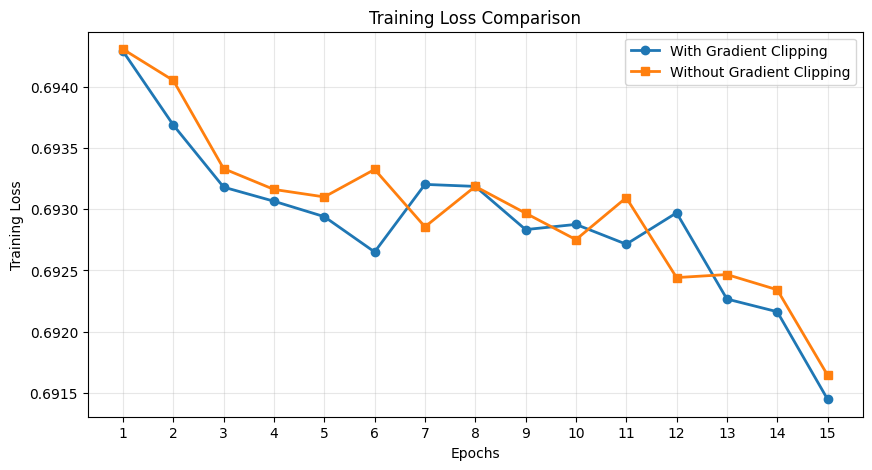

In [143]:
epochs = range(1, 16)

plt.figure(figsize=(10, 5))

plt.plot(epochs, result_A["losses"],
         marker="o", linewidth=2,
         label="With Gradient Clipping")

plt.plot(epochs, result_B["losses"],
         marker="s", linewidth=2,
         label="Without Gradient Clipping")

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

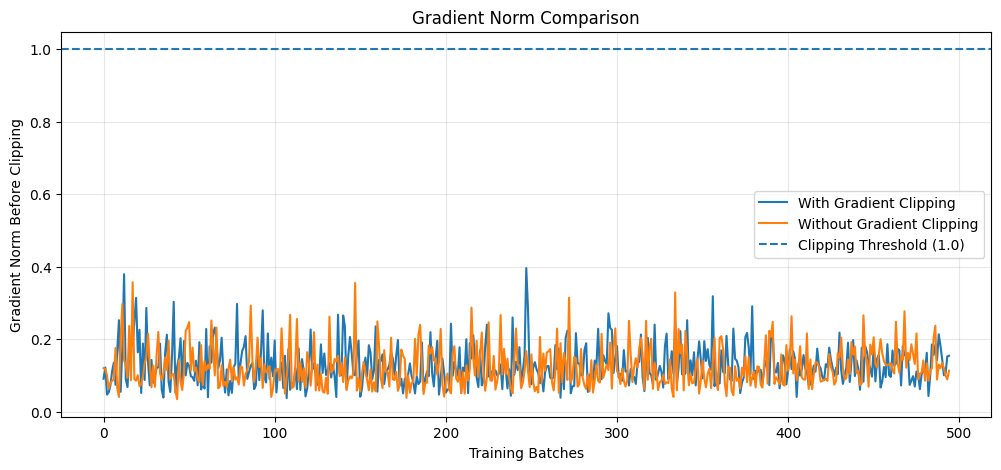

In [144]:
plt.figure(figsize=(12, 5))

plt.plot(result_A["gradient_norms"],
         label="With Gradient Clipping")

plt.plot(result_B["gradient_norms"],
         label="Without Gradient Clipping")

plt.axhline(y=1.0, linestyle="--",
            label="Clipping Threshold (1.0)")

plt.title("Gradient Norm Comparison")
plt.xlabel("Training Batches")
plt.ylabel("Gradient Norm Before Clipping")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

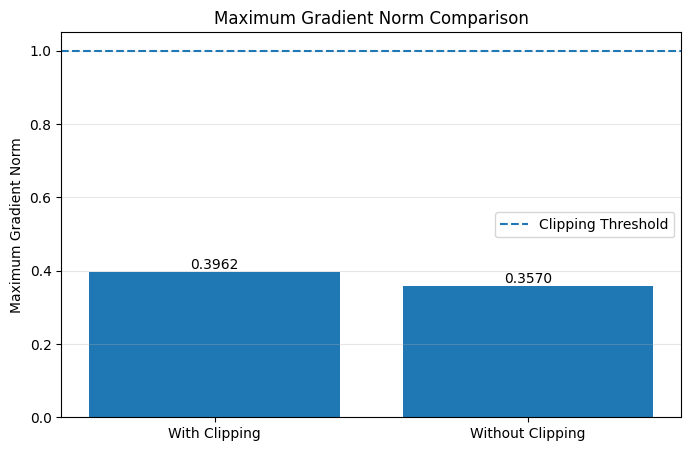

In [145]:
models = ["With Clipping", "Without Clipping"]

max_norms = [
    result_A["max_gradient_norm"],
    result_B["max_gradient_norm"]
]

plt.figure(figsize=(8, 5))

bars = plt.bar(models, max_norms)

plt.axhline(y=1.0, linestyle="--",
            label="Clipping Threshold")

plt.title("Maximum Gradient Norm Comparison")
plt.ylabel("Maximum Gradient Norm")
plt.legend()
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{bar.get_height():.4f}",
        ha="center",
        va="bottom"
    )

plt.show()